# Marvel CPG Data V3 — Missing-Day Analysis and Reconciliation Experiments

**Data version:** V3 (client correction received 2026-10-16)  
**Decision goal:** determine whether the repaired Delivery–restock relationship supports defensible missing-day inventory reconstruction and improves the inputs to Module 2.

This notebook has two governed parts:

1. **Deep EDA and reconciliation:** reporting gaps, explicit restocks, Delivery foreign keys, inventory-flow equations, missing-gap closure, promotions, and execution audits.
2. **Controlled missing-data experiments:** artificially hide fully observed 1–4 day blocks, reconstruct them with competing methods, and compare sales, inventory, and OOS-state errors.

June 2026 is the locked test month. It is not loaded or evaluated. March and April are development folds; May is reserved as the validation gate in the Module 2 notebook.

## Governance rules

- A missing Sell-out row means **unknown / not reported**, never zero.
- Observed values are not overwritten; estimates use separate columns.
- `restock_units` and `restock_delivery_id` are accepted only after the contract checks below pass.
- An actual delivery may update inventory on or before prediction date `t`; a future actual-delivery date is never used as a model feature.
- Planned future replenishment must be represented using order and scheduled-delivery information known by `t`.
- Artificial masking evaluates imputations against known observations. Naturally missing daily sales remain unknown and are not treated as ground truth.

In [1]:
from __future__ import annotations

import json
import os
import warnings
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/marvel-v3-mpl")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "figure.figsize": (11, 5)})
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)

SEED = 650
TEST_START = pd.Timestamp("2026-06-01")
DEV_END = pd.Timestamp("2026-04-30")
TARGETS = {"precision": 0.75, "recall": 0.70, "roc_auc": 0.80}

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "data/raw/fact_sell_out.csv").exists())
DATA = ROOT / "data/raw"
OUTPUT = ROOT / "outputs/v3/missing_analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)
print("Output:", OUTPUT)
print("Locked test begins:", TEST_START.date())


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig
	/Users/william/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/william/.cache/fontconfig

Matplotlib is building the font cache; this may take a moment.


Repository: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote
Output: /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/outputs/v3/missing_analysis
Locked test begins: 2026-06-01


## 1. Load V3 data without touching the locked test

In [2]:
def read_before_test(path: Path, date_col: str, chunksize: int = 250_000) -> pd.DataFrame:
    parts = []
    for chunk in pd.read_csv(path, parse_dates=[date_col], chunksize=chunksize):
        parts.append(chunk.loc[chunk[date_col] < TEST_START])
    result = pd.concat(parts, ignore_index=True)
    assert result[date_col].max() < TEST_START
    return result

stores = pd.read_csv(DATA / "dim_stores.csv")
products = pd.read_csv(DATA / "dim_products.csv")
promotions = pd.read_csv(DATA / "dim_promotions.csv", parse_dates=["start_date", "end_date"])
guardrails = pd.read_csv(DATA / "dim_guardrails.csv")
sell_out = read_before_test(DATA / "fact_sell_out.csv", "date")
sell_in = read_before_test(DATA / "fact_sell_in.csv", "date")
audits = read_before_test(DATA / "fact_execution_audits.csv", "date")
deliveries = pd.read_csv(
    DATA / "fact_deliveries.csv",
    parse_dates=["order_date", "scheduled_delivery", "actual_delivery"],
)
deliveries = deliveries.loc[
    (deliveries.order_date < TEST_START) & (deliveries.actual_delivery < TEST_START)
].copy()

source_summary = pd.DataFrame([
    {"table": "sell_out", "rows_pre_June": len(sell_out), "max_date": sell_out.date.max()},
    {"table": "sell_in", "rows_pre_June": len(sell_in), "max_date": sell_in.date.max()},
    {"table": "deliveries", "rows_pre_June": len(deliveries), "max_date": deliveries.actual_delivery.max()},
    {"table": "execution_audits", "rows_pre_June": len(audits), "max_date": audits.date.max()},
])
display(source_summary)

,table,rows_pre_June,max_date
0,sell_out,2073376,2026-05-31
1,sell_in,259286,2026-05-25
2,deliveries,134742,2026-05-31
3,execution_audits,196930,2026-05-31


### 1.1 V3 contract checks

In [3]:
checks = []
def check(area, statement, passed, detail=""):
    checks.append({"area": area, "check": statement, "passed": bool(passed), "detail": detail})

check("keys", "Sell-out date/store/SKU is unique", not sell_out.duplicated(["date", "store_id", "sku_id"]).any())
check("keys", "Delivery ID is unique", deliveries.delivery_id.is_unique)
check("logic", "OOS equals zero end-of-day inventory", sell_out.is_out_of_stock.eq(sell_out.inventory_level.eq(0)).all())
check("restock", "Positive restock always has delivery ID", sell_out.loc[sell_out.restock_units.gt(0), "restock_delivery_id"].notna().all())
check("restock", "Delivery ID appears only on positive restock", sell_out.loc[sell_out.restock_delivery_id.notna(), "restock_units"].gt(0).all())
check("delivery", "delay_days equals actual minus scheduled", deliveries.delay_days.eq((deliveries.actual_delivery - deliveries.scheduled_delivery).dt.days).all())
check("delivery", "Early means exactly -1 day", deliveries.loc[deliveries.delivery_status.str.startswith("Early"), "delay_days"].eq(-1).all())
check("delivery", "On Time means zero days", deliveries.loc[deliveries.delivery_status.str.startswith("On Time"), "delay_days"].eq(0).all())
check("delivery", "Short Ship iff delivered < ordered", deliveries.delivery_status.str.contains("Short Ship").eq(deliveries.units_delivered.lt(deliveries.units_ordered)).all())
check("delivery", "No delivery after data end", deliveries.actual_delivery.le(pd.Timestamp("2026-06-30")).all())
expected_fill = deliveries.units_delivered / deliveries.units_ordered * 100
check("delivery", "Fill rate agrees at stored 2-decimal precision", np.isclose(deliveries.fill_rate_pct, expected_fill, atol=.00501).all())
check("sell-in", "Every invoice date is Monday", sell_in.date.dt.dayofweek.eq(0).all())

audit_pairs = audits[["store_id", "sku_id"]].drop_duplicates()
so_pairs = sell_out[["store_id", "sku_id"]].drop_duplicates()
audit_pair_check = audit_pairs.merge(so_pairs, on=["store_id", "sku_id"], how="left", indicator=True)
check("audit", "All audit store-SKU pairs exist in Sell-out", audit_pair_check._merge.eq("both").all())

contract_checks = pd.DataFrame(checks)
display(contract_checks)
assert contract_checks.passed.all(), "A required V3 data contract failed"

,area,check,passed,detail
0,keys,Sell-out date/store/SKU is unique,True,
1,keys,Delivery ID is unique,True,
2,logic,OOS equals zero end-of-day inventory,True,
3,restock,Positive restock always has delivery ID,True,
4,restock,Delivery ID appears only on positive restock,True,
5,delivery,delay_days equals actual minus scheduled,True,
6,delivery,Early means exactly -1 day,True,
7,delivery,On Time means zero days,True,
8,delivery,Short Ship iff delivered < ordered,True,
9,delivery,No delivery after data end,True,


## 2. Canonical calendar and missingness profile

,metric,value
0,active store-SKU pairs,4.375000e+03
1,calendar rows pre-June,2.257500e+06
2,account-day coverage through April,9.185520e-01
3,account-day missing rate through April,8.144796e-02


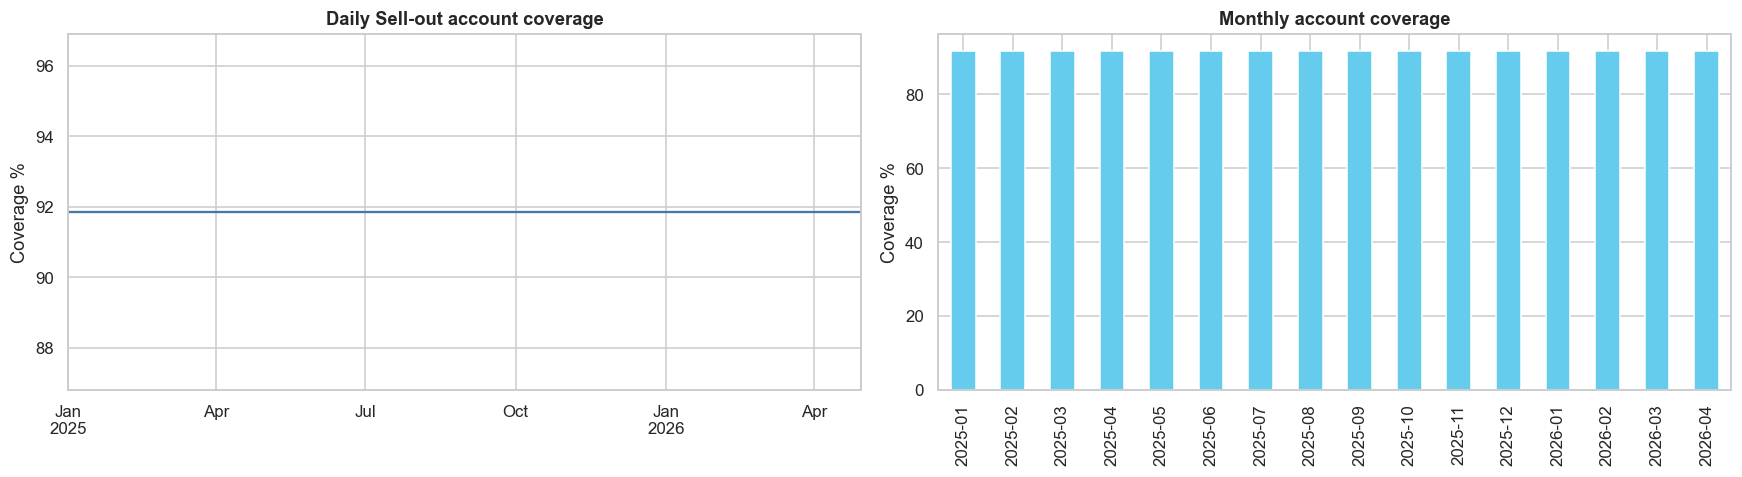

In [4]:
pairs = (
    sell_out[["store_id", "sku_id"]].drop_duplicates()
    .merge(stores[["store_id", "channel", "region", "segment_tier"]], on="store_id", validate="many_to_one")
    .merge(products[["sku_id", "category", "is_msl"]], on="sku_id", validate="many_to_one")
)
calendar = pd.DataFrame({"date": pd.date_range(sell_out.date.min(), pd.Timestamp("2026-05-31"))})
pairs["_k"] = 1
calendar["_k"] = 1
panel = pairs.merge(calendar, on="_k").drop(columns="_k")
panel = panel.merge(sell_out, on=["date", "store_id", "sku_id"], how="left", validate="one_to_one")
panel = panel.sort_values(["store_id", "sku_id", "date"]).reset_index(drop=True)
panel["is_reported"] = panel.inventory_level.notna()
panel["data_status"] = np.where(panel.is_reported, "Observed", "Unknown")
panel["weekday"] = panel.date.dt.dayofweek

account_day = panel.groupby(["date", "store_id"], observed=True).is_reported.all().rename("reported").reset_index()
dev_account_day = account_day.loc[account_day.date <= DEV_END].copy()
coverage = dev_account_day.reported.mean()
daily = dev_account_day.groupby("date").reported.mean().mul(100).rename("coverage_pct")
monthly = dev_account_day.assign(month=dev_account_day.date.dt.to_period("M")).groupby("month").reported.mean().mul(100)

missingness_summary = pd.DataFrame({
    "metric": ["active store-SKU pairs", "calendar rows pre-June", "account-day coverage through April", "account-day missing rate through April"],
    "value": [len(pairs), len(panel), coverage, 1 - coverage],
})
display(missingness_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
daily.plot(ax=axes[0], color="#4477AA")
axes[0].set(title="Daily Sell-out account coverage", ylabel="Coverage %", xlabel="")
monthly.plot.bar(ax=axes[1], color="#66CCEE")
axes[1].set(title="Monthly account coverage", ylabel="Coverage %", xlabel="")
plt.tight_layout(); plt.show()

,gap_days,runs,share_pct
0,1,7437,92.373618
1,2,555,6.893554
2,3,54,0.670724
3,4,4,0.049683
4,5,1,0.012421


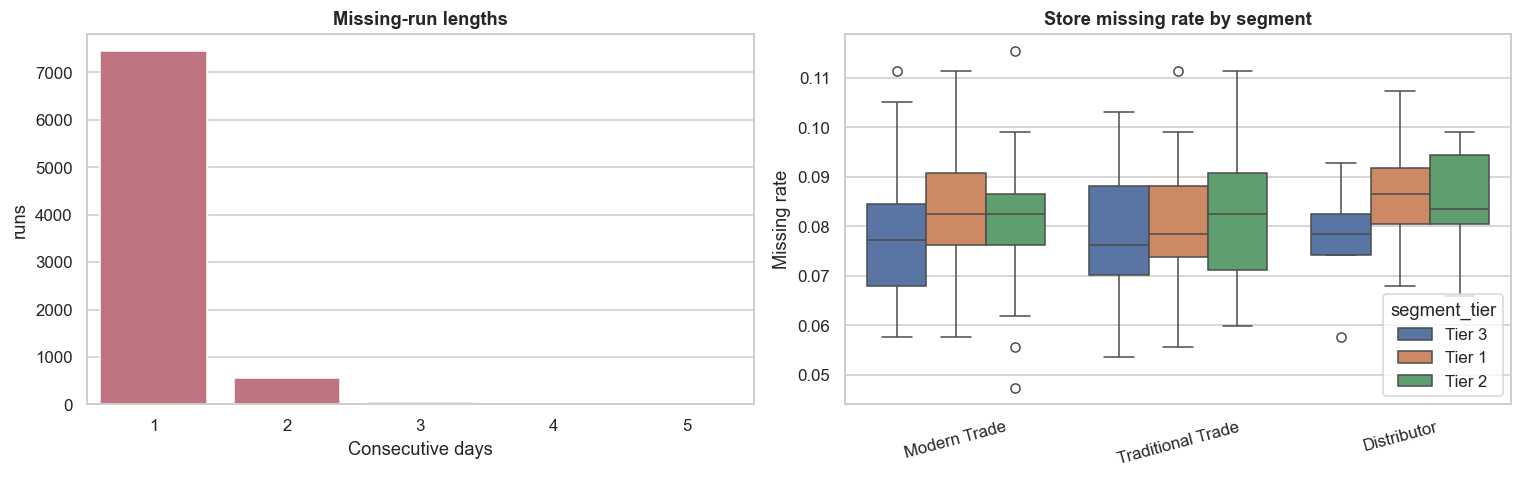

In [5]:
def missing_runs(frame: pd.DataFrame) -> pd.DataFrame:
    x = frame.sort_values(["store_id", "date"]).copy()
    x["missing"] = ~x.reported
    x["run"] = x.groupby("store_id").missing.transform(lambda s: s.ne(s.shift()).cumsum())
    return x.loc[x.missing].groupby(["store_id", "run"], as_index=False).agg(
        start=("date", "min"), end=("date", "max"), days=("date", "size")
    )

runs = missing_runs(dev_account_day)
run_summary = runs.days.value_counts().sort_index().rename_axis("gap_days").reset_index(name="runs")
run_summary["share_pct"] = run_summary.runs / run_summary.runs.sum() * 100
display(run_summary)

store_missing = (1 - dev_account_day.groupby("store_id").reported.mean()).rename("missing_rate").reset_index()
store_missing = store_missing.merge(stores[["store_id", "channel", "segment_tier"]], on="store_id")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=run_summary, x="gap_days", y="runs", color="#CC6677", ax=axes[0])
axes[0].set(title="Missing-run lengths", xlabel="Consecutive days")
sns.boxplot(data=store_missing, x="channel", y="missing_rate", hue="segment_tier", ax=axes[1])
axes[1].set(title="Store missing rate by segment", xlabel="", ylabel="Missing rate")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

## 3. Explicit restock ↔ Delivery reconciliation

In [6]:
restocks = sell_out.loc[sell_out.restock_units.gt(0), [
    "date", "store_id", "sku_id", "restock_units", "restock_delivery_id"
]].copy()
linked = restocks.merge(
    deliveries[["delivery_id", "store_id", "sku_id", "actual_delivery", "units_delivered"]],
    left_on="restock_delivery_id", right_on="delivery_id", how="left", validate="one_to_one",
    suffixes=("_sellout", "_delivery"),
)
linked["fk_resolves"] = linked.delivery_id.notna()
linked["date_match"] = linked.date.eq(linked.actual_delivery)
linked["store_match"] = linked.store_id_sellout.eq(linked.store_id_delivery)
linked["sku_match"] = linked.sku_id_sellout.eq(linked.sku_id_delivery)
linked["quantity_match"] = linked.restock_units.eq(linked.units_delivered)

linkage_summary = pd.DataFrame({
    "metric": ["positive restock rows", "foreign key resolves", "date matches", "store matches", "SKU matches", "quantity matches"],
    "value": [len(linked), linked.fk_resolves.mean(), linked.date_match.mean(), linked.store_match.mean(), linked.sku_match.mean(), linked.quantity_match.mean()],
})
display(linkage_summary)
assert linked[["fk_resolves", "date_match", "store_match", "sku_match", "quantity_match"]].all().all()

linked_ids = set(restocks.restock_delivery_id.dropna())
delivery_coverage = deliveries.assign(linked_to_sellout=deliveries.delivery_id.isin(linked_ids))
missing_keys = panel.loc[~panel.is_reported, ["date", "store_id", "sku_id"]].drop_duplicates()
unlinked = delivery_coverage.loc[~delivery_coverage.linked_to_sellout].merge(
    missing_keys, left_on=["actual_delivery", "store_id", "sku_id"], right_on=["date", "store_id", "sku_id"],
    how="left", indicator=True,
)
delivery_link_summary = pd.DataFrame({
    "metric": ["all pre-June deliveries", "linked to observed restock", "unlinked deliveries", "unlinked occurring on missing Sell-out day"],
    "value": [len(deliveries), delivery_coverage.linked_to_sellout.sum(), len(unlinked), unlinked._merge.eq("both").sum()],
})
display(delivery_link_summary)

,metric,value
0,positive restock rows,123623.0
1,foreign key resolves,1.0
2,date matches,1.0
3,store matches,1.0
4,SKU matches,1.0
5,quantity matches,1.0


,metric,value
0,all pre-June deliveries,134742
1,linked to observed restock,123623
2,unlinked deliveries,11119
3,unlinked occurring on missing Sell-out day,11119


### 3.1 Inventory-flow identity on consecutive observed days

In [7]:
observed = sell_out.sort_values(["store_id", "sku_id", "date"]).copy()
g_obs = observed.groupby(["store_id", "sku_id"], observed=True, sort=False)
observed["prev_date"] = g_obs.date.shift()
observed["prev_inventory"] = g_obs.inventory_level.shift()
observed["gap_days"] = (observed.date - observed.prev_date).dt.days
observed["expected_inventory"] = observed.prev_inventory - observed.units_sold_daily + observed.restock_units
observed["balance_error"] = observed.inventory_level - observed.expected_inventory
consecutive = observed.loc[observed.gap_days.eq(1)].copy()

balance_summary = pd.DataFrame({
    "metric": ["consecutive observed transitions", "exact inventory equations", "maximum absolute error", "negative inventory"],
    "value": [len(consecutive), consecutive.balance_error.eq(0).sum(), consecutive.balance_error.abs().max(), observed.inventory_level.lt(0).sum()],
})
display(balance_summary)
assert consecutive.balance_error.eq(0).all()

by_restock = consecutive.assign(has_restock=consecutive.restock_units.gt(0)).groupby("has_restock").agg(
    rows=("date", "size"), exact_balance=("balance_error", lambda s: s.eq(0).mean()),
    mean_units_sold=("units_sold_daily", "mean"), mean_end_inventory=("inventory_level", "mean"),
)
display(by_restock)

,metric,value
0,consecutive observed transitions,1899743.0
1,exact inventory equations,1899743.0
2,maximum absolute error,0.0
3,negative inventory,0.0


,rows,exact_balance,mean_units_sold,mean_end_inventory
has_restock,,,,
False,1786281,1.0,5.316921,102.841800
True,113462,1.0,6.656123,178.737172


**Interpretation:** V3 repairs the central V2 limitation. A positive Sell-out restock is now a confirmed Delivery event with the same date, store, SKU, and units. The remaining deliveries are not contradictory: they occur on days where the Sell-out row itself is missing. This allows Delivery to be used as a known inventory inflow during a reporting gap.

## 4. Natural missing gaps: can known deliveries close the inventory bridge?

,has_gap_delivery,gaps,mean_gap_days,mean_delivery_units,nonnegative_implied_sales,median_implied_sales_per_day
0,False,148011,1.076298,0.000000,1.0,0.0
1,True,21247,1.132019,93.797289,1.0,29.0


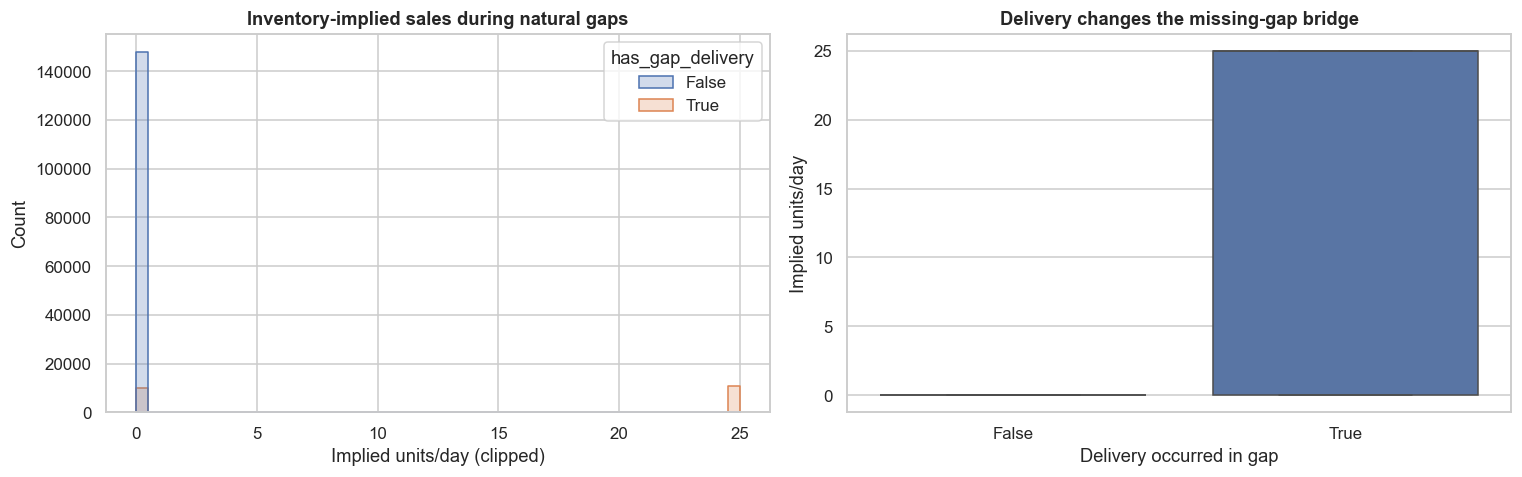

In [8]:
delivery_daily = deliveries.groupby(["actual_delivery", "store_id", "sku_id"], as_index=False).agg(
    delivery_units=("units_delivered", "sum"), delivery_count=("delivery_id", "size")
).rename(columns={"actual_delivery": "date"})
panel = panel.merge(delivery_daily, on=["date", "store_id", "sku_id"], how="left")
panel[["delivery_units", "delivery_count"]] = panel[["delivery_units", "delivery_count"]].fillna(0)

panel["delivery_cumulative"] = panel.groupby(["store_id", "sku_id"], observed=True).delivery_units.cumsum()
observed_bridge = panel.loc[panel.is_reported, [
    "date", "store_id", "sku_id", "channel", "segment_tier", "inventory_level", "units_sold_daily", "delivery_cumulative"
]].copy()
gb = observed_bridge.groupby(["store_id", "sku_id"], observed=True, sort=False)
observed_bridge["prev_date"] = gb.date.shift()
observed_bridge["prev_inventory"] = gb.inventory_level.shift()
observed_bridge["gap_days"] = (observed_bridge.date - observed_bridge.prev_date).dt.days
observed_bridge["deliveries_since_previous_report"] = observed_bridge.delivery_cumulative - gb.delivery_cumulative.shift()
observed_bridge["implied_sales_on_missing_days"] = (
    observed_bridge.prev_inventory + observed_bridge.deliveries_since_previous_report
    - observed_bridge.units_sold_daily - observed_bridge.inventory_level
)
gaps = observed_bridge.loc[observed_bridge.gap_days.gt(1)].copy()
gaps["missing_days"] = gaps.gap_days - 1
gaps["has_gap_delivery"] = gaps.deliveries_since_previous_report.gt(0)
gaps["implied_sales_per_missing_day"] = gaps.implied_sales_on_missing_days / gaps.missing_days

gap_bridge_summary = gaps.groupby("has_gap_delivery", observed=True).agg(
    gaps=("date", "size"),
    mean_gap_days=("missing_days", "mean"),
    mean_delivery_units=("deliveries_since_previous_report", "mean"),
    nonnegative_implied_sales=("implied_sales_on_missing_days", lambda s: s.ge(0).mean()),
    median_implied_sales_per_day=("implied_sales_per_missing_day", "median"),
).reset_index()
display(gap_bridge_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=gaps, x=gaps.implied_sales_per_missing_day.clip(-5, 25), hue="has_gap_delivery", bins=50, element="step", ax=axes[0])
axes[0].set(title="Inventory-implied sales during natural gaps", xlabel="Implied units/day (clipped)")
sns.boxplot(data=gaps, x="has_gap_delivery", y=gaps.implied_sales_per_missing_day.clip(-5, 25), ax=axes[1])
axes[1].set(title="Delivery changes the missing-gap bridge", xlabel="Delivery occurred in gap", ylabel="Implied units/day")
plt.tight_layout(); plt.show()

The bridge equation identifies **aggregate** sales over a natural missing interval, not the exact daily path. It is therefore suitable for plausibility checks and interval-level reconciliation. Daily estimator quality must be measured with artificial masking, where the hidden truth is known.

## 5. Promotion and execution signals that affect sales estimation

In [9]:
promo_map = promotions.set_index("promo_id")
promo_rows = sell_out.loc[sell_out.promo_id.notna()].copy()
promo_discount_match = np.isclose(
    promo_rows.promo_discount_pct,
    promo_map.loc[promo_rows.promo_id, "discount_pct"].to_numpy(),
).mean()

in_stock = sell_out.loc[~sell_out.is_out_of_stock].copy()
in_stock["on_promo"] = in_stock.promo_id.notna()
in_stock["month"] = in_stock.date.dt.to_period("M")
baseline = in_stock.loc[~in_stock.on_promo].groupby(["store_id", "sku_id", "month"]).units_sold_daily.mean()
promo_days = in_stock.loc[in_stock.on_promo].join(baseline.rename("normal_units"), on=["store_id", "sku_id", "month"]).dropna(subset=["normal_units"])
promo_days = promo_days.merge(promotions[["promo_id", "promo_type"]], on="promo_id")
promo_uplift = promo_days.groupby("promo_type").agg(rows=("date", "size"), promo_units=("units_sold_daily", "mean"), baseline_units=("normal_units", "mean"))
promo_uplift["uplift_pct"] = (promo_uplift.promo_units / promo_uplift.baseline_units - 1) * 100

audit_sums = audits.merge(products[["sku_id", "category"]], on="sku_id").groupby(["store_id", "date", "category"]).shelf_share_pct.sum()
audit_summary = pd.DataFrame({
    "metric": ["promotion discount exact-match rate", "audit category-visit sums within 0.031 pp of 100", "maximum shelf-share sum deviation"],
    "value": [promo_discount_match, np.isclose(audit_sums, 100, atol=.031).mean(), (audit_sums - 100).abs().max()],
})
display(audit_summary)
display(promo_uplift.round(3))

audit_sales = audits.merge(sell_out[["date", "store_id", "sku_id", "units_sold_daily", "is_out_of_stock"]], on=["date", "store_id", "sku_id"])
audit_sales = audit_sales.loc[~audit_sales.is_out_of_stock]
execution_assoc = pd.DataFrame([
    {"signal": "secondary_display", "level": str(k), "mean_units": d.units_sold_daily.mean(), "rows": len(d)}
    for k, d in audit_sales.groupby("secondary_display")
] + [
    {"signal": "planogram_compliance", "level": str(k), "mean_units": d.units_sold_daily.mean(), "rows": len(d)}
    for k, d in audit_sales.groupby("planogram_compliance")
])
display(execution_assoc)

,metric,value
0,promotion discount exact-match rate,1.00
1,audit category-visit sums within 0.031 pp of 100,1.00
2,maximum shelf-share sum deviation,0.03


,rows,promo_units,baseline_units,uplift_pct
promo_type,,,,
BOGO,16455,8.420,6.830,23.284
Bundle,52832,7.286,7.124,2.277
Display,41785,5.137,4.614,11.341
Feature,31690,6.874,6.079,13.079
TPR,116716,6.966,6.063,14.887
Volume,41332,6.916,5.769,19.868


,signal,level,mean_units,rows
0,secondary_display,False,6.392078,85784
1,secondary_display,True,8.258845,84452
2,planogram_compliance,False,5.177217,28056
3,planogram_compliance,True,7.740625,142180


## 6. Artificial masking design

In [10]:
# Planned promotion calendar, including days where Sell-out is missing.
promo_parts = []
for r in promotions.itertuples(index=False):
    promo_parts.append(pd.DataFrame({
        "date": pd.date_range(r.start_date, min(r.end_date, pd.Timestamp("2026-05-31"))),
        "channel": r.channel, "category": r.category,
        "promo_planned": True, "promo_discount_planned": r.discount_pct,
    }))
promo_calendar = pd.concat(promo_parts, ignore_index=True).drop_duplicates(["date", "channel", "category"])
panel = panel.merge(promo_calendar, on=["date", "channel", "category"], how="left")
panel["promo_planned"] = panel.promo_planned.fillna(False)
panel["promo_discount_planned"] = panel.promo_discount_planned.fillna(0)

pair = panel.groupby(["store_id", "sku_id"], observed=True, sort=False)
panel["sales_median_28"] = pair.units_sold_daily.transform(lambda s: s.shift(1).rolling(28, min_periods=5).median())
panel["sales_weekday_8"] = panel.groupby(["store_id", "sku_id", "weekday"], observed=True).units_sold_daily.transform(
    lambda s: s.shift(1).rolling(8, min_periods=2).median()
)
fallback = panel.groupby(["channel", "category"], observed=True).units_sold_daily.transform("median")
panel["sales_base"] = panel.sales_weekday_8.fillna(panel.sales_median_28).fillna(fallback).clip(lower=0)

# Frozen pre-validation promotion multipliers; this is associative, not causal.
factor_source = panel.loc[(panel.date <= pd.Timestamp("2026-02-21")) & panel.is_reported & ~panel.is_out_of_stock.fillna(False)].copy()
normal = factor_source.loc[~factor_source.promo_planned].groupby(["channel", "category"]).units_sold_daily.mean()
promoted = factor_source.loc[factor_source.promo_planned].groupby(["channel", "category"]).units_sold_daily.mean()
promo_factors = (promoted / normal).clip(.8, 1.8).replace([np.inf, -np.inf], np.nan).fillna(1).to_dict()
panel["promo_factor"] = [promo_factors.get((c, k), 1.0) if p else 1.0 for c, k, p in zip(panel.channel, panel.category, panel.promo_planned)]
panel["sales_promo"] = panel.sales_base * panel.promo_factor

FOLDS = {
    "March": (pd.Timestamp("2026-03-01"), pd.Timestamp("2026-03-24")),
    "April": (pd.Timestamp("2026-04-01"), pd.Timestamp("2026-04-23")),
}

In [11]:
def sample_blocks(frame, start, end, gap_days, n=1500):
    d = frame.loc[frame.date.between(start - pd.Timedelta(days=1), end)].copy()
    observed_wide = d.pivot(index=["store_id", "sku_id"], columns="date", values="is_reported").fillna(False)
    candidates = []
    for block_start in pd.date_range(start, end - pd.Timedelta(days=gap_days - 1)):
        needed = [block_start - pd.Timedelta(days=1), *pd.date_range(block_start, periods=gap_days)]
        valid = observed_wide.reindex(columns=needed, fill_value=False).all(axis=1)
        candidates.extend((store, sku, block_start) for store, sku in observed_wide.index[valid])
    result = pd.DataFrame(candidates, columns=["store_id", "sku_id", "start"])
    return result.sample(min(n, len(result)), random_state=SEED + gap_days)

def evaluate_blocks(frame, fold, gap_days):
    start, end = FOLDS[fold]
    blocks = sample_blocks(frame, start, end, gap_days)
    index = frame.set_index(["store_id", "sku_id", "date"])
    rows = []
    for b in blocks.itertuples(index=False):
        prior = index.loc[(b.store_id, b.sku_id, b.start - pd.Timedelta(days=1))]
        hidden = index.loc[(b.store_id, b.sku_id, slice(b.start, b.start + pd.Timedelta(days=gap_days - 1))), :].reset_index()
        cumulative_base = hidden.sales_base.cumsum()
        cumulative_promo = hidden.sales_promo.cumsum()
        cumulative_delivery = hidden.delivery_units.cumsum()
        predictions = {
            "LOCF": np.repeat(prior.inventory_level, gap_days),
            "sales_depletion": (prior.inventory_level - cumulative_base).clip(lower=0),
            "promotion_depletion": (prior.inventory_level - cumulative_promo).clip(lower=0),
            "delivery_reconciled": (prior.inventory_level + cumulative_delivery - cumulative_promo).clip(lower=0),
        }
        sales_predictions = {
            "LOCF": np.zeros(gap_days),
            "sales_depletion": hidden.sales_base.to_numpy(),
            "promotion_depletion": hidden.sales_promo.to_numpy(),
            "delivery_reconciled": hidden.sales_promo.to_numpy(),
        }
        for method, inventory in predictions.items():
            for i in range(gap_days):
                rows.append({
                    "fold": fold, "gap_days": gap_days, "method": method,
                    "store_id": b.store_id, "sku_id": b.sku_id,
                    "channel": hidden.channel.iloc[i], "segment_tier": hidden.segment_tier.iloc[i],
                    "has_delivery": bool(hidden.delivery_units.sum() > 0),
                    "actual_sales": hidden.units_sold_daily.iloc[i], "pred_sales": sales_predictions[method][i],
                    "actual_inventory": hidden.inventory_level.iloc[i], "pred_inventory": inventory.iloc[i] if hasattr(inventory, "iloc") else inventory[i],
                    "actual_oos": bool(hidden.is_out_of_stock.iloc[i]), "pred_oos": bool(inventory.iloc[i] <= 0 if hasattr(inventory, "iloc") else inventory[i] <= 0),
                })
    return pd.DataFrame(rows)

mask_results = pd.concat([
    evaluate_blocks(panel, fold, gap)
    for fold in FOLDS for gap in [1, 2, 3, 4]
], ignore_index=True)
print(f"Artificially masked evaluation rows: {len(mask_results):,}")

Artificially masked evaluation rows: 120,000


## 7. Imputation results

### Overall

,method,rows,sales_MAE,sales_WAPE,inventory_MAE,inventory_WAPE,inventory_bias,OOS_precision,OOS_recall
1,delivery_reconciled,30000.0,2.2761,0.3863,2.9707,0.0222,0.0075,0.9752,0.8994
2,promotion_depletion,30000.0,2.2761,0.3863,13.7357,0.1024,-0.0770,0.7079,0.8994
3,sales_depletion,30000.0,2.3405,0.3973,13.8687,0.1034,-0.0727,0.7097,0.8911
0,LOCF,30000.0,5.8915,1.0000,19.3108,0.1440,0.0018,0.7531,0.7124


### Gaps with and without a delivery

,has_delivery,method,rows,sales_MAE,sales_WAPE,inventory_MAE,inventory_WAPE,inventory_bias,OOS_precision,OOS_recall
0,False,LOCF,24736.0,5.6477,1.0000,11.1550,0.0902,0.0902,1.0000,0.7132
1,False,delivery_reconciled,24736.0,2.2408,0.3968,2.8592,0.0231,0.0086,0.9760,0.8978
2,False,promotion_depletion,24736.0,2.2408,0.3968,2.8592,0.0231,0.0086,0.9760,0.8978
3,False,sales_depletion,24736.0,2.2996,0.4072,3.1169,0.0252,0.0130,0.9809,0.8887
4,True,LOCF,5264.0,7.0370,1.0000,57.6360,0.3145,-0.2784,0.2877,0.7072
5,True,delivery_reconciled,5264.0,2.4417,0.3470,3.4947,0.0191,0.0041,0.9701,0.9097
6,True,promotion_depletion,5264.0,2.4417,0.3470,64.8453,0.3539,-0.3483,0.2564,0.9097
7,True,sales_depletion,5264.0,2.5328,0.3599,64.3927,0.3514,-0.3446,0.2571,0.9065


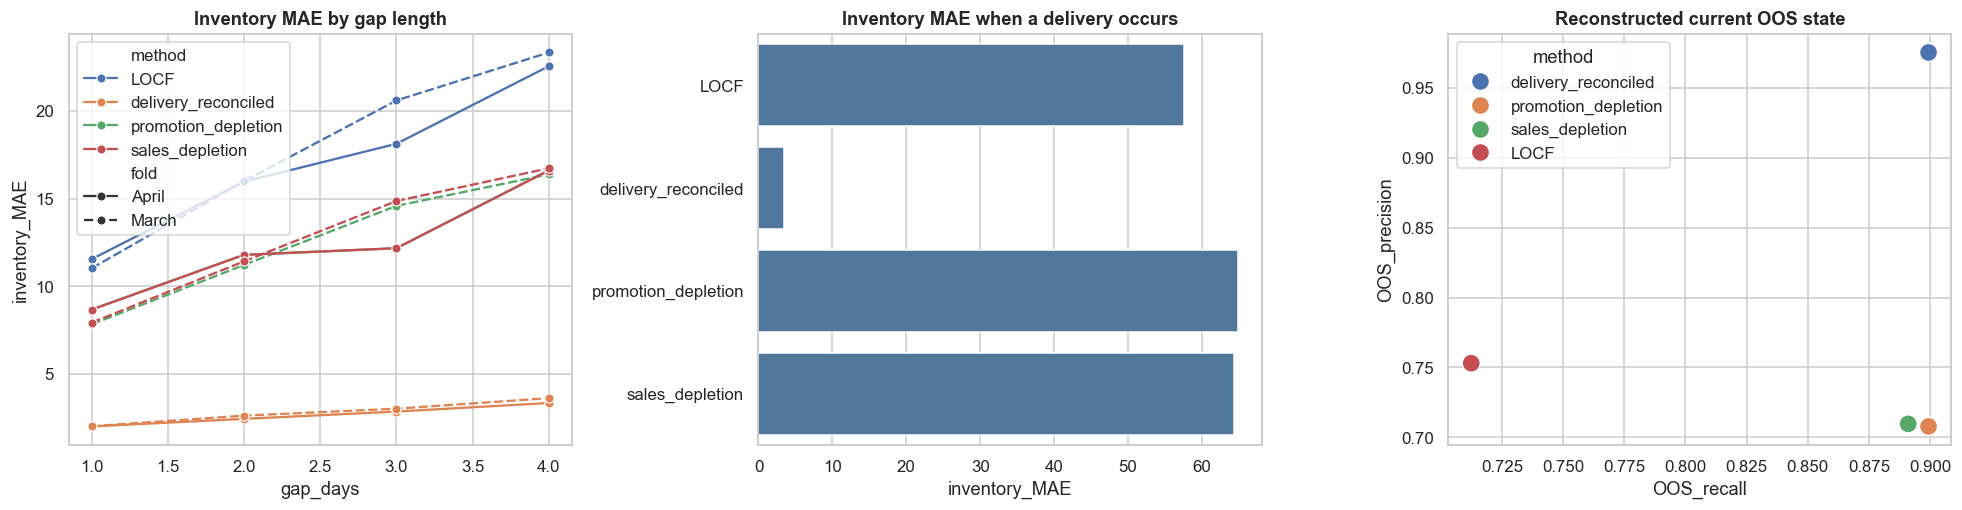

In [12]:
def summarize(d):
    sales_error = d.pred_sales - d.actual_sales
    inventory_error = d.pred_inventory - d.actual_inventory
    tp = (d.pred_oos & d.actual_oos).sum()
    fp = (d.pred_oos & ~d.actual_oos).sum()
    fn = (~d.pred_oos & d.actual_oos).sum()
    return pd.Series({
        "rows": len(d),
        "sales_MAE": sales_error.abs().mean(),
        "sales_WAPE": sales_error.abs().sum() / max(d.actual_sales.sum(), 1),
        "inventory_MAE": inventory_error.abs().mean(),
        "inventory_WAPE": inventory_error.abs().sum() / max(d.actual_inventory.sum(), 1),
        "inventory_bias": inventory_error.sum() / max(d.actual_inventory.sum(), 1),
        "OOS_precision": tp / max(tp + fp, 1),
        "OOS_recall": tp / max(tp + fn, 1),
    })

masking_summary = mask_results.groupby(["fold", "gap_days", "method"], observed=True).apply(summarize).reset_index()
overall_masking = mask_results.groupby("method", observed=True).apply(summarize).reset_index().sort_values("inventory_MAE")
delivery_masking = mask_results.groupby(["has_delivery", "method"], observed=True).apply(summarize).reset_index()
segment_masking = mask_results.groupby(["channel", "segment_tier", "method"], observed=True).apply(summarize).reset_index()
display(Markdown("### Overall")); display(overall_masking.round(4))
display(Markdown("### Gaps with and without a delivery")); display(delivery_masking.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.lineplot(data=masking_summary, x="gap_days", y="inventory_MAE", hue="method", style="fold", marker="o", ax=axes[0])
axes[0].set(title="Inventory MAE by gap length")
sns.barplot(data=delivery_masking.loc[delivery_masking.has_delivery], y="method", x="inventory_MAE", ax=axes[1], color="#4477AA")
axes[1].set(title="Inventory MAE when a delivery occurs", ylabel="")
sns.scatterplot(data=overall_masking, x="OOS_recall", y="OOS_precision", hue="method", s=140, ax=axes[2])
axes[2].set(title="Reconstructed current OOS state")
plt.tight_layout(); plt.show()

## 8. Governed decision and exports

In [13]:
selected_method = overall_masking.iloc[0].method
v3_decision = {
    "data_version": "v3",
    "test_start": str(TEST_START.date()),
    "test_loaded_or_evaluated": False,
    "delivery_restock_relationship": "validated explicit one-to-one restock linkage",
    "selected_missing_inventory_method": selected_method,
    "module_2_targets": TARGETS,
}
decision_table = pd.DataFrame([
    {"decision": "Delivery-to-restock relationship", "result": "Validated: date/store/SKU/units match 100% on explicit restocks"},
    {"decision": "Unlinked deliveries", "result": "Explained by missing Sell-out rows; use as known inflow during gaps"},
    {"decision": "Natural missing daily sales", "result": "Not directly observed; interval total can be reconciled, daily path must be estimated"},
    {"decision": "Selected masking method", "result": selected_method},
    {"decision": "June test", "result": "Locked and not evaluated"},
])
display(decision_table)

contract_checks.to_csv(OUTPUT / "contract_checks.csv", index=False)
missingness_summary.to_csv(OUTPUT / "missingness_summary.csv", index=False)
run_summary.to_csv(OUTPUT / "missing_run_summary.csv", index=False)
linkage_summary.to_csv(OUTPUT / "restock_delivery_linkage.csv", index=False)
delivery_link_summary.to_csv(OUTPUT / "delivery_coverage.csv", index=False)
balance_summary.to_csv(OUTPUT / "inventory_balance_checks.csv", index=False)
gap_bridge_summary.to_csv(OUTPUT / "natural_gap_bridge.csv", index=False)
promo_uplift.reset_index().to_csv(OUTPUT / "promotion_uplift.csv", index=False)
masking_summary.to_csv(OUTPUT / "masking_metrics.csv", index=False)
overall_masking.to_csv(OUTPUT / "masking_overall.csv", index=False)
delivery_masking.to_csv(OUTPUT / "masking_by_delivery.csv", index=False)
segment_masking.to_csv(OUTPUT / "masking_by_segment.csv", index=False)
(OUTPUT / "decision_summary.json").write_text(json.dumps(v3_decision, indent=2), encoding="utf-8")
print("Saved evidence to", OUTPUT)

,decision,result
0,Delivery-to-restock relationship,Validated: date/store/SKU/units match 100% on ...
1,Unlinked deliveries,Explained by missing Sell-out rows; use as kno...
2,Natural missing daily sales,Not directly observed; interval total can be r...
3,Selected masking method,delivery_reconciled
4,June test,Locked and not evaluated


Saved evidence to /Users/william/Documents/Codex/2026-09-29/github-plugin-github-openai-curated-remote/outputs/v3/missing_analysis


## Reading the result

The V3 correction changes the business conclusion: Delivery is no longer an unreconciled logistics-only signal. It is the explicit source of restock units. This does **not** reveal the exact daily sales on naturally missing days, but it makes inventory reconstruction materially more defensible—especially when a delivery occurs inside the gap. The Module 2 notebook next tests whether past inventory, demand velocity, and **known pending scheduled replenishment** reduce false positives on the untouched May validation period.